<a href="https://colab.research.google.com/github/hrishabh1212/Machine-Learning/blob/main/LINER_REGRESSION_AGE_VS_GULCOSE_Synthetic_clinical_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving synthetic_clinical_dataset_1000.csv to synthetic_clinical_dataset_1000.csv


   Age     Glucose
0   56  115.438134
1   69  153.651670
2   46  125.435521
3   32   98.246595
4   60  116.294924

Intercept: 69.34740989083929
Coefficient: 1.0195402889135776

Regression Equation:
Glucose = 69.35 + (1.02 × Age)

Model Evaluation
MSE: 64.79
MAE: 6.37
R² Score: 0.849


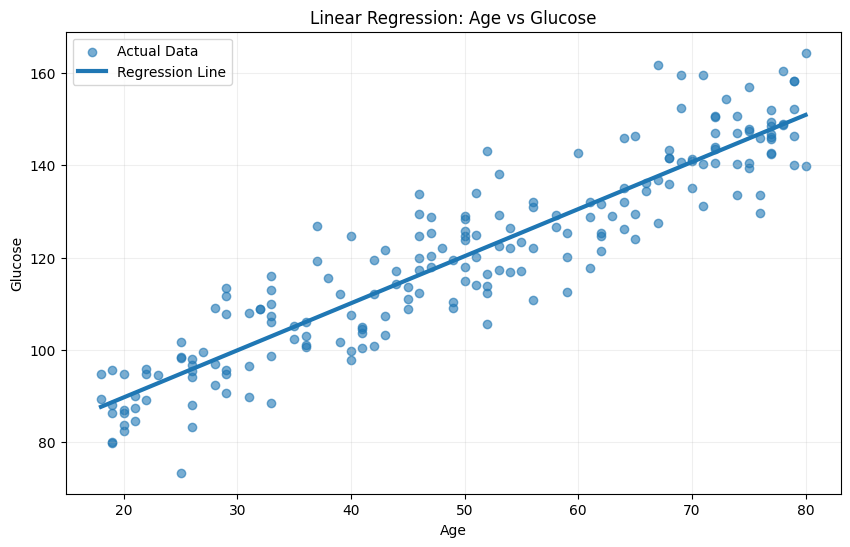

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ==========================================
# 1. Create synthetic data
# ==========================================

np.random.seed(42)

n = 1000

age = np.random.randint(18, 81, n)

# Positive relationship between Age and Glucose
noise = np.random.normal(0, 8, n)
glucose = 70 + (1.0 * age) + noise

# Keep glucose in a realistic range
glucose = np.clip(glucose, 70, 180)

df = pd.DataFrame({
    "Age": age,
    "Glucose": glucose
})

print(df.head())

# ==========================================
# 2. Define X and y
# ==========================================

X = df[["Age"]]
y = df["Glucose"]

# ==========================================
# 3. Train-test split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# ==========================================
# 4. Linear Regression
# ==========================================

model = LinearRegression()
model.fit(X_train, y_train)

# ==========================================
# 5. Prediction
# ==========================================

y_pred = model.predict(X_test)

# ==========================================
# 6. Regression equation
# ==========================================

print("\nIntercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

print("\nRegression Equation:")
print(
    f"Glucose = {model.intercept_:.2f} + "
    f"({model.coef_[0]:.2f} × Age)"
)

# ==========================================
# 7. Model Evaluation
# ==========================================

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation")
print("MSE:", round(mse, 2))
print("MAE:", round(mae, 2))
print("R² Score:", round(r2, 3))

# ==========================================
# 8. Sort data for clean regression line
# ==========================================

sorted_data = pd.DataFrame({
    "Age": X_test["Age"].values,
    "Prediction": y_pred
}).sort_values("Age")

# ==========================================
# 9. Plot
# ==========================================

plt.figure(figsize=(10, 6))

plt.scatter(
    X_test["Age"],
    y_test,
    alpha=0.6,
    label="Actual Data"
)

plt.plot(
    sorted_data["Age"],
    sorted_data["Prediction"],
    linewidth=3,
    label="Regression Line"
)

plt.xlabel("Age")
plt.ylabel("Glucose")
plt.title("Linear Regression: Age vs Glucose")

plt.legend()
plt.grid(alpha=0.2)

plt.show()